# 5b) Debug Core/Substituent Split

Focused debug notebook for inspecting how the current functions in `atlas_functions.py` split a ligand into coordination core and substituent fragments.

Current example: `ACAHUJ02`, to diagnose why the visualized substituent fragment appears to gain additional hydrogens.

In [10]:
import os
import sys

import scope
from IPython.display import SVG, display
from rdkit import Chem
from rdkit.Chem import Draw

sys.path.insert(0, os.path.abspath('..'))
from atlas_functions import (
    color_atom_labels, core_family_label, get_metal_bound_ligand_atoms,
    get_weights, split_core_substituent,
)

## User Configuration

In [11]:
data_path     = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/"                    # Update with your path
analysis_path = "/Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/"  # Update with your path 
env_path      = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy" # Update with your path
save_figures  = True

# Figures Path
if save_figures: figures_path = "/Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/"       # Update with your path
else:            figures_path = None 

# Normalizes the configured strings and defines the analysis output folder.
data_path     = os.path.abspath(os.path.expanduser(data_path)) + os.sep
env_path      = os.path.abspath(os.path.expanduser(env_path))
outputs_path  = analysis_path + "Outputs/"

# Loads Environment
env = scope.load_binary(env_path)

# Required Outputs
thermo_path     = outputs_path + 'unique_thermodynamic_data.csv'

print(f"Data directory:    {data_path}")
print(f"SCOPE environment: {env_path}")

Data directory:    /Users/sergivela/Documents/SCOPE/ATLAS/Data/
SCOPE environment: /Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy


## Selects System to Illustrate Ligand core-substituent splitting 

In [12]:
debug_sys_name = "ACAHUJ02"
debug_sys      = scope.load_binary(data_path + f"2-Systems/{debug_sys_name}/{debug_sys_name}.npy")

In [13]:

hs_ref_mol              = debug_sys.find_source("ref_hs_mol")[1]
ligand                  = hs_ref_mol.ligands[0]
lig_mol, smiles         = ligand.rdkit_obj, ligand.smiles
donor_atoms             = get_metal_bound_ligand_atoms(ligand)
core_atoms, subs_atoms  = split_core_substituent(ligand, mols=False)
core_mol, subs_mol      = split_core_substituent(ligand, mols=True)
core_label              = core_family_label(core_mol)
weights, lig_distances  = get_weights(ligand)

print('refcode:', debug_sys.refcode)
print('ligand smiles:', smiles)
print('ligand atoms:', lig_mol.GetNumAtoms())
print('core_atoms:', core_atoms)
print('subs_atoms:', subs_atoms)
print('core family:', core_label)
print('core atoms in mol:', core_mol.GetNumAtoms())
print('subs atoms in mol:', subs_mol.GetNumAtoms())

refcode: ACAHUJ02
ligand smiles: [H]C(=Nc1c([H])c([H])c(OC([H])([H])[H])c([H])c1[H])c1nc([H])c([H])n1[H]
ligand atoms: 26
core_atoms: [ 0  4  5 18 19 20 21 22 23 24 25]
subs_atoms: [ 1  2  3  6  7  8  9 10 11 12 13 14 15 16 17]
core family: hybrid[scaffold=1x[C3N2];sites=C3N2:donors=1:distance=1;eff. connectivity=N2]
core atoms in mol: 11
subs atoms in mol: 15


## Drawings

The core drawing reports the complete family label. Effective connectivity is annotated only for donor atoms whose value enters that label: all donors in a fully acyclic core, or the non-ring donors in a hybrid core.

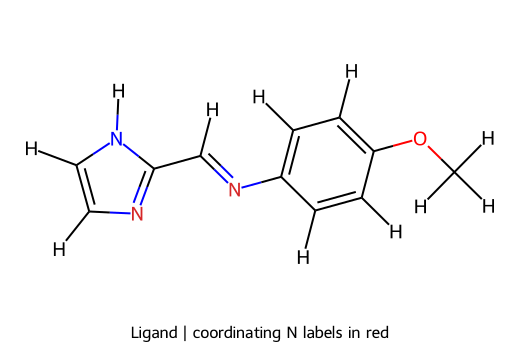

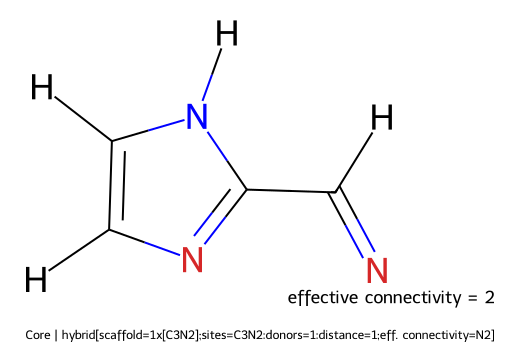

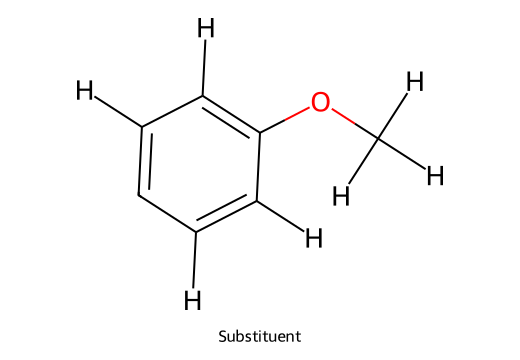

In [14]:
def display_svg_mol(mol, legend, donor_atoms=()):
    donor_atoms = sorted(int(idx) for idx in donor_atoms)
    svg = Draw.MolsToGridImage([mol], molsPerRow=1, subImgSize=(520, 360), legends=[legend], useSVG=True)
    svg_text = svg.data if hasattr(svg, 'data') else str(svg)
    display(SVG(color_atom_labels(svg_text, donor_atoms)))

labelled_core_mol = Chem.Mol(core_mol)
core_ring_atoms = {idx for ring in labelled_core_mol.GetRingInfo().AtomRings() for idx in ring}
for atom in labelled_core_mol.GetAtoms():
    is_donor = atom.HasProp('_MetalDonor') and atom.GetBoolProp('_MetalDonor')
    if is_donor and (not core_ring_atoms or atom.GetIdx() not in core_ring_atoms):
        atom.SetProp('atomNote', f"effective connectivity = {atom.GetIntProp('_LigandEffectiveDegree')}")
core_donor_atoms = [atom.GetIdx() for atom in labelled_core_mol.GetAtoms() if atom.HasProp('_MetalDonor') and atom.GetBoolProp('_MetalDonor')]

display_svg_mol(lig_mol, 'Ligand | coordinating N labels in red', donor_atoms)
display_svg_mol(labelled_core_mol, f'Core | {core_label}', core_donor_atoms)
display_svg_mol(subs_mol, 'Substituent')

## Highlight Split On Parent Ligand

Green atoms are the core and blue atoms are substituent atoms; the coordinating N labels are shown in red. The lighter core and substituent colors retain the underlying molecular structure. This drawing keeps the original parent ligand connectivity and is useful for deciding whether the split itself is chemically right.

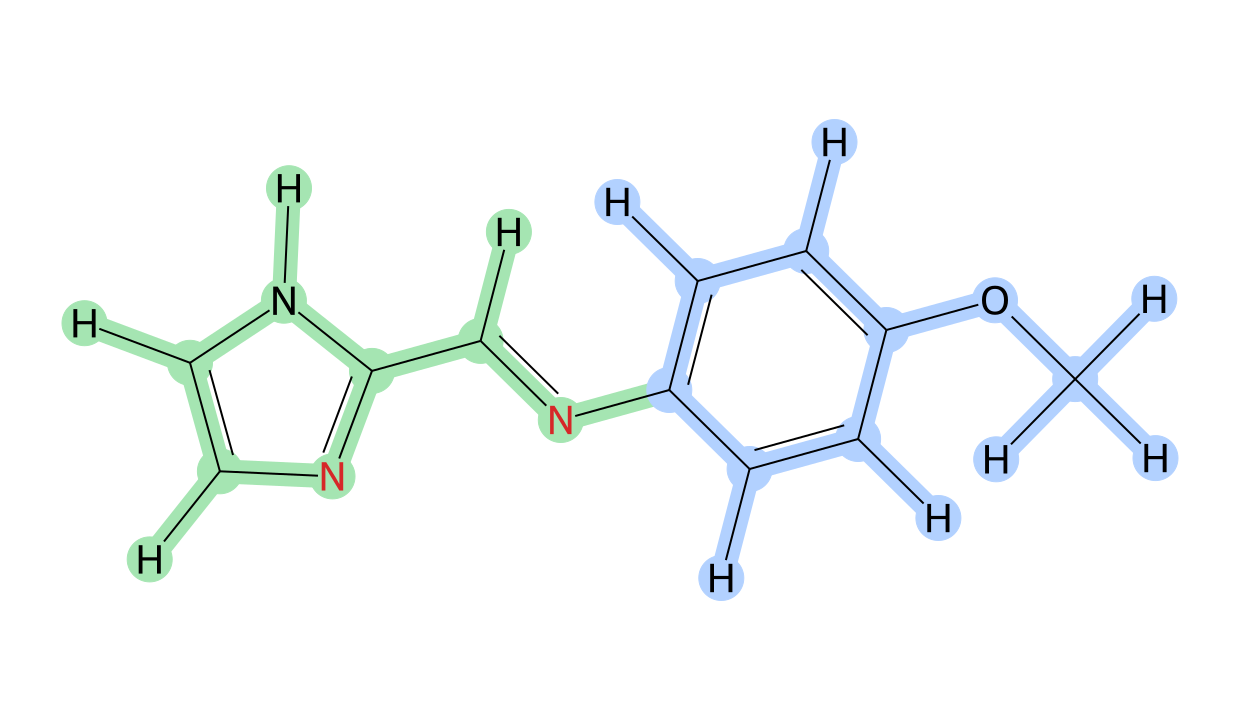

In [15]:
highlight_atoms = sorted(int(idx) for idx in set(core_atoms) | set(subs_atoms))
highlight_colors = {int(idx): (0.65, 0.90, 0.70) for idx in core_atoms}
highlight_colors.update({int(idx): (0.70, 0.82, 1.00) for idx in subs_atoms})
from subprocess import run

fig_path = f"{figures_path}/{debug_sys_name}_core_substituent_split.png"

svg_path = fig_path.replace('.png', '.svg')

fig = Draw.MolsToGridImage(
    [lig_mol],
    molsPerRow=1,
    subImgSize=(1240, 720),
    highlightAtomLists=[highlight_atoms],
    highlightAtomColors=[highlight_colors],
    useSVG=True,
)
svg_text = fig.data if hasattr(fig, 'data') else str(fig)
svg_text = color_atom_labels(svg_text, donor_atoms)

with open(svg_path, 'w') as f:
    f.write(svg_text)
run(['sips', '-s', 'format', 'png', svg_path, '--out', fig_path], check=True, capture_output=True)
os.remove(svg_path)
display(SVG(svg_text))